**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_045_초급_회귀_태양광발전량예측

### **태양광 발전량 예측 — <span style="color:darkgreen">시간당 발전량(kW)</span> 예측 모델 개발**
---

- 도메인 : 태양광 발전량 예측
- 목  표 : 발전소의 시간당 발전량(kW)을 예측하는 인공지능모델 개발
- 운영팀은 기상·설비 데이터로 발전량과 이상 징후를 예측하는 모델을 개발하려 한다.
- 발전량 편차가 커 다솜썬는 정확한 발전량 예측으로 계통 연계 손실을 줄이려 한다.
- 분석에는 약 1,080건 규모의 발전소 데이터가 제공된다.
- 모델이 시간당 발전량(kW)을 신뢰할 만한 수준으로 예측하면 현업의 대응 비용을 줄일 수 있을 것으로 기대한다.

---

#### **[유의사항]**
- 각 문항의 답은 `# (번호) 정답을 입력하세요` 셀의 `정답01` ~ `정답14` 변수에 **값만** 입력합니다. 채점은 이 값으로만 합니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 다솜썬의 데이터로 발전소의 시간당 발전량(kW)을 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, median, groupby, quantile, copy, clip, drop, fillna, sum, isnull, loc, value_counts, isin, get_dummies, info, DataFrame, sort_values, columns, shape) · seaborn(jointplot, barplot) · matplotlib(show) · scikit-learn(train_test_split, StandardScaler, fit_transform, transform, KNeighborsRegressor, fit, DecisionTreeRegressor, feature_importances_, predict, mean_absolute_error) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, Dense, evaluate)
- 난이도 : 초급 (설계 난이도 점수 2.7 / 5)
- 예상 소요 시간 : 약 122분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 태양광 발전량 예측 (에너지)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- Power_Kw              : 시간당 발전량(kW)
- E_Sample_Id           : 표본 식별번호
- FE_Irradiance         : 일사량(W/㎡)
- FE_Panel_Temp         : 패널 온도(℃)
- FE_Wind_Ms            : 풍속(m/s)
- FE_Humidity           : 습도(%)
- FE_Cloud_Pct          : 운량(%)
- FE_Dust_Idx           : 패널 오염 지수
- FE_Inverter_Eff       : 인버터 효율(%)
- FE_Tilt_Deg           : 패널 경사각(도)
- FE_Panel_Age_Y        : 패널 사용 연수(년)
- E_Site                : 발전소
- E_Panel_Type          : 패널 종류 (복수 값은 | 로 결합되어 있음)
- E_Season              : 계절
- E_Mount               : 설치 방식

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **1. 데이터 분석을 위해 pandas 라이브러리를 사용하려고 합니다. 아래 가이드의 별칭(alias)으로 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd) | 난이도: 기초 | 예상 시간: 3분</sub>

- 사용할 라이브러리 : `pandas`
- as 뒤에 쓸 이름(alias) : `pd`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 답안 셀에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [26]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import pandas as pd

In [ ]:
# (1) 정답을 입력하세요 — `정답01` 에 값만 넣고 실행하세요

정답01 = None

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 2글자이고 첫 글자는 `p` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import pandas as p_

정답01 = 'p_'   # 빈칸에 넣은 단어
```

</details>

### **2. AI 모델링을 위해 분석 및 처리할 데이터 파일을 읽어오려고 합니다. pandas로 데이터 파일을 읽어온 뒤, 데이터프레임 변수명 df_raw 에 할당하고 첫 3개 행을 출력하세요.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 파일은 이 노트북과 같은 폴더에 있습니다
    - 데이터 파일명 : data.csv
    - 저장할 변수 이름 : df_raw
- **[정답02]** 읽어 온 데이터의 **숫자형이 아닌(문자열) 컬럼의 개수** 를 기입하세요
- 답안 : **[정답02]** 의 값만 답안 셀에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [27]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
import pandas as pd

df_raw = pd.read_csv('./data.csv')
df_raw.head(3)

print(df_raw.select_dtypes(exclude='number').shape[1])

5


In [ ]:
# (2) 정답을 입력하세요 — `정답02` 에 값만 넣고 실행하세요

정답02 = None

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요. 읽어 온 df_raw 로 숫자형이 아닌(문자열) 컬럼의 개수를 직접 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`, `shape`, `select_dtypes`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df_raw = pd.read_csv('./data.csv')
df_raw.head(3)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
print(df_raw.select_dtypes(exclude='____').shape[__])
```

</details>

### **3. 계절(E_Season) 별로 풍속(m/s)(FE_Wind_Ms)의 특성을 비교할 계획입니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(median, groupby) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 계절(E_Season) 별 풍속(m/s)(FE_Wind_Ms)의 **중앙값** 을 구해 변수 `grp` 에 보관하세요
    - 대상 데이터프레임 : df_raw
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 답안 셀에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [28]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

grp = df_raw.groupby('E_Season')['FE_Wind_Ms'].median()
grp

,FE_Wind_Ms
E_Season,
가을,2.4
겨울,2.6
봄,2.4
여름,2.2


In [ ]:
# (3) 정답을 입력하세요 — `정답03` 에 값만 넣고 실행하세요

정답03 = None

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

범주별로 묶어서 하나의 통계량을 구하는 패턴입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `groupby`, `median`. 정답은 7글자이고 첫 글자는 `g` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
grp = df_raw.grou___('E_Season')['FE_Wind_Ms'].median()
grp

정답03 = 'grou___'   # 빈칸에 넣은 단어
```

</details>

### **4. 그래프를 통해 운량(%)(FE_Cloud_Pct)와(과) 인버터 효율(%)(FE_Inverter_Eff)의 분포와 관계를 함께 확인하고자 합니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(jointplot) · matplotlib(show) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 대상 데이터프레임 : df_raw
- seaborn 의 jointplot 으로 시각화하세요
- X축: FE_Cloud_Pct, Y축: FE_Inverter_Eff
- 그래프 종류(kind)는 'scatter' 로 지정하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 답안 셀에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

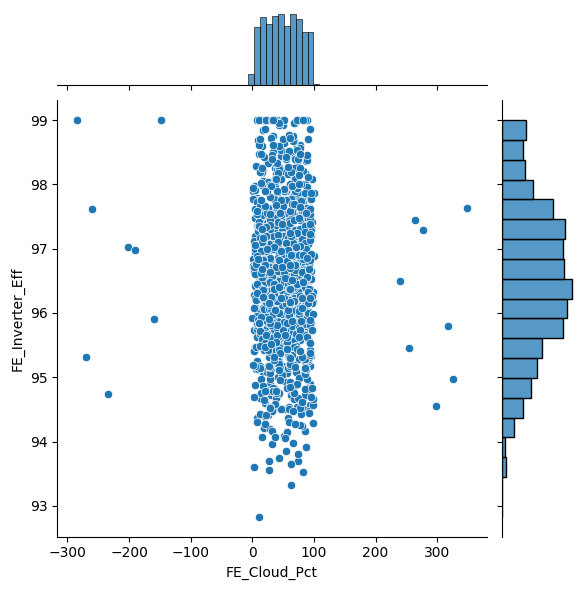

In [29]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.jointplot(data=df_raw, x='FE_Cloud_Pct', y='FE_Inverter_Eff', kind='scatter')
plt.show()

In [ ]:
# (4) 정답을 입력하세요 — `정답04` 에 값만 넣고 실행하세요

정답04 = None

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

두 변수의 관계와 각각의 분포를 한 그림에 그리는 그래프입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `sns.jointplot`. 정답은 4글자이고 첫 글자는 `k` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.jointplot(data=df_raw, x='FE_Cloud_Pct', y='FE_Inverter_Eff', ki__='scatter')
plt.show()

정답04 = 'ki__'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 운량(%)(FE_Cloud_Pct) 컬럼의 극단값을 상·하위 1% 경계값으로 대체하고자 합니다.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, copy, clip, drop) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_raw
    - FE_Cloud_Pct 의 1% 분위수를 low, 99% 분위수를 high 로 산출하세요 (변수명: low, high)
    - low 보다 작은 값은 low 로, high 보다 큰 값은 high 로 바꾸세요(행 삭제 없음)
    - 식별자 컬럼 E_Sample_Id 를 삭제한 사본에 적용해 df_clean 에 담으세요
- **[정답05]** 처리 후 FE_Cloud_Pct 의 **최솟값**을 소수점 둘째 자리까지 입력하세요
- 답안 : **[정답05]** 의 값만 답안 셀에 `정답05 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [30]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
low, high = df_raw['FE_Cloud_Pct'].quantile([0.01, 0.99])

df_clean = df_raw.drop(columns=['E_Sample_Id']).copy()
df_clean['FE_Cloud_Pct'] = df_clean['FE_Cloud_Pct'].clip(lower=low, upper=high)

# [정답05] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
df_clean['FE_Cloud_Pct'].min()


1.0

In [ ]:
# (5) 정답을 입력하세요 — `정답05` 에 값만 넣고 실행하세요

정답05 = 1.00

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

분위수 두 개를 한 번에 구한 뒤 clip 에 하한/상한으로 넣습니다. 처리된 컬럼의 최솟값은 low 이상 high 이하입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `quantile`, `clip`, `min`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
low, high = df_raw['FE_Cloud_Pct'].quantile([0.01, 0.99])

df_clean = df_raw.drop(columns=['E_Sample_Id']).copy()
df_clean['FE_Cloud_Pct'] = df_clean['FE_Cloud_Pct'].clip(lower=low, upper=high)

# [정답05] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
df_clean['____'].min()
```

</details>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다. 제시된 가이드에 맞춰 결측치를 확인하고 처리하십시오.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(copy, fillna, median, sum) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 5번 `df_clean`
- 대상 데이터프레임 : df_clean
- 다음 지침에 따라 결측치를 처리하고 검증하는데 에러가 나고 있습니다. 코드의 오류를 수정하세요
    - 수치형 컬럼(FE_Dust_Idx, FE_Panel_Age_Y)의 결측치는 **중앙값** 으로 채우세요
    - 처리가 반영된 데이터프레임은 변수명 df_filled 에 저장하고, 남은 결측치 개수를 출력하세요
- **[정답06]** 처리 전 df_clean 의 결측치는 총 몇 개로 나타나나요?
- 답안 : **[정답06]** 의 값만 답안 셀에 `정답06 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [32]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

df_filled = df_clean.copy()
df_filled['FE_Dust_Idx'] = df_filled['FE_Dust_Idx'].fillna(df_filled['FE_Dust_Idx'].median())
df_filled['FE_Panel_Age_Y'] = df_filled['FE_Panel_Age_Y'].fillna(df_filled['FE_Panel_Age_Y'].median())
print(df_filled.isnull().sum().sum())
print(df_clean.isnull().sum().sum())

0
167


In [33]:
# (6) 정답을 입력하세요 — `정답06` 에 값만 넣고 실행하세요

정답06 = 167

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

결측치를 중앙값/최빈값으로 채우는 흐름을 점검하세요. 결측치 처리 전 데이터프레임의 결측치 합계를 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
df_filled = df_clean.copy()
df_filled['FE_Dust_Idx'] = df_filled['FE_Dust_Idx'].fillna(df_filled['FE_Dust_Idx'].median())
df_filled['FE_Panel_Age_Y'] = df_filled['FE_Panel_Age_Y'].fillna(df_filled['FE_Panel_Age_Y'].median())
print(df_filled.isnull().sum().sum())

# [정답06] 실행한 결과를 입력하세요
df_clean.isnull().sum().sum()
```

</details>

### **7. 원-핫 인코딩(One-Hot Encoding)은 범주형 데이터를 1과 0의 이진형 벡터로 변환하는 방법입니다. 아래 안내대로 범주형 데이터를 처리하고 인코딩하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(loc, value_counts, isin, get_dummies) | 난이도: 어려움 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `df_filled`
- 제시된 가이드에 맞춰 데이터를 처리하는 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_filled
    - 패널 종류(E_Panel_Type) 의 값 '다결정|단결정', '다결정|박막' 을(를) '다결정' 으로 치환하세요
    - 패널 종류(E_Panel_Type) 의 값 '단결정|다결정', '단결정|박막' 을(를) '단결정' 으로 치환하세요
    - 패널 종류(E_Panel_Type) 의 값 '박막|다결정', '박막|단결정' 을(를) '박막' 으로 치환하세요
    - 치환 후 범주별 개수를 출력하세요
- 남은 문자열 컬럼을 모두 원-핫 인코딩(get_dummies, drop_first=True)하는데 에러가 나고 있습니다. 코드의 오류를 정정하고 결과를 df_final 에 담으세요
- **[정답07]** 인코딩 후 df_final 의 **전체 컬럼 개수**는 몇 개로 나타나나요?
- 답안 : **[정답07]** 의 값만 답안 셀에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [38]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요 (채점하지 않음)

df_filled.loc[df_filled['E_Panel_Type'].isin(['다결정|단결정', '다결정|박막']), 'E_Panel_Type'] = '다결정'
df_filled.loc[df_filled['E_Panel_Type'].isin(['단결정|다결정', '단결정|박막']), 'E_Panel_Type'] = '단결정'
df_filled.loc[df_filled['E_Panel_Type'].isin(['박막|다결정', '박막|단결정']), 'E_Panel_Type'] = '박막'

print(df_filled['E_Panel_Type'].loc())

In [35]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

df_final = pd.get_dummies(data=df_filled, columns=['E_Site', 'E_Panel_Type', 'E_Season', 'E_Mount'], drop_first=True)
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1077 entries, 0 to 1076
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Power_Kw          1077 non-null   float64
 1   FE_Irradiance     1077 non-null   float64
 2   FE_Panel_Temp     1077 non-null   float64
 3   FE_Wind_Ms        1077 non-null   float64
 4   FE_Humidity       1077 non-null   float64
 5   FE_Cloud_Pct      1077 non-null   float64
 6   FE_Dust_Idx       1077 non-null   float64
 7   FE_Inverter_Eff   1077 non-null   float64
 8   FE_Tilt_Deg       1077 non-null   float64
 9   FE_Panel_Age_Y    1077 non-null   float64
 10  E_Site_B소         1077 non-null   bool   
 11  E_Site_C소         1077 non-null   bool   
 12  E_Site_D소         1077 non-null   bool   
 13  E_Panel_Type_단결정  1077 non-null   bool   
 14  E_Panel_Type_박막   1077 non-null   bool   
 15  E_Season_겨울       1077 non-null   bool   
 16  E_Season_봄        1077 non-null   bool   


In [40]:
# (7) 정답을 입력하세요 — `정답07` 에 값만 넣고 실행하세요

정답07 = 20

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

빈칸을 채워 치환 코드를 완성해 실행하세요. 값별 개수를 세는 Series 메서드입니다. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `isin`, `loc`, `value_counts`, `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df_filled.loc[df_filled['E_Panel_Type'].isin(['다결정|단결정', '다결정|박막']), 'E_Panel_Type'] = '다결정'
df_filled.loc[df_filled['E_Panel_Type'].isin(['단결정|다결정', '단결정|박막']), 'E_Panel_Type'] = '단결정'
df_filled.loc[df_filled['E_Panel_Type'].isin(['박막|다결정', '박막|단결정']), 'E_Panel_Type'] = '박막'

print(df_filled['E_Panel_Type'].value_counts())

df_final = pd.get_dummies(data=df_filled, columns=['E_Site', 'E_Panel_Type', 'E_Season', 'E_Mount'], drop_first=True)
df_final.info()

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
df_final.shape[__]
```

</details>

### **8. 훈련과 검증 데이터셋을 분리하고, 검증 레이블의 분포를 확인할 계획입니다.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 보통 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 7번 `df_final`
- 대상 데이터프레임 : df_final
- 시간당 발전량(kW)(Power_Kw) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 대입하세요
- 분리에는 sklearn.model_selection 의 train_test_split 을 사용하세요
- 데이터를 훈련 70 : 검증 30 로 분할합니다 (test_size=0.3)
- 변수명 : X_train, X_valid, y_train, y_valid (훈련 피처/검증 피처/훈련 레이블/검증 레이블)
- random_state 는 100 로 고정하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답08]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답08]** 의 값만 답안 셀에 `정답08 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [41]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

from sklearn.model_selection import train_test_split

X = df_final.drop('Power_Kw', axis=1)
y = df_final['Power_Kw']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=100)

In [42]:
# (8) 정답을 입력하세요 — `정답08` 에 값만 넣고 실행하세요

정답08 = 'train_test_split'

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`. 정답은 16글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
from sklearn.model_selection import train_test_split

X = df_final.drop('Power_Kw', axis=1)
y = df_final['Power_Kw']

X_train, X_valid, y_train, y_valid = train_te________(X, y, test_size=0.3, random_state=100)

정답08 = 'train_te________'   # 빈칸에 넣은 단어
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (표준화(평균 0, 표준편차 1))**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(StandardScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 제시된 가이드에 맞춰 스케일링 처리하는데 에러가 나고 있습니다. 코드의 오류를 바로잡으세요
    - sklearn.preprocessing 에서 StandardScaler 를 import 하세요
    - StandardScaler 를 ss 변수에 할당하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 저장하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 저장하세요
- **[정답09]** StandardScaler 적용 후 검증 데이터(X_valid)의 **최솟값**을 소수 둘째 자리까지 입력하세요
- 답안 : **[정답09]** 의 값만 답안 셀에 `정답09 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [44]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)

print(X_valid.min())

-3.156443251020109


In [45]:
# (9) 정답을 입력하세요 — `정답09` 에 값만 넣고 실행하세요

정답09 = -3.16

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최솟값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.min`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.min(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 시간당 발전량(kW)(Power_Kw)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. KNN와(과) DecisionTree는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(KNeighborsRegressor, fit, DecisionTreeRegressor) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- KNN 모델을 아래와 같이 만들어 `knn` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_neighbors=7, weights='uniform'
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- DecisionTree 모델을 아래와 같이 만들어 `dt` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : max_depth=4, min_samples_leaf=2
    - 난수 시드(random_state) : 1
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `knn`(KNN) 의 **훈련 데이터** 점수 `knn.score(X_train, y_train)` (결정계수(R2))를 소수점 셋째 자리까지 작성하세요
- 답안 : **[정답10]** 의 값만 답안 셀에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [49]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(n_neighbors=7, weights='uniform')
knn.fit(X_train, y_train)

from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth=4, min_samples_leaf=2, random_state=1)
dt.fit(X_train, y_train)

round(knn.score(X_train, y_train), 3)

0.415

In [ ]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)



In [50]:
# (10) 정답을 입력하세요 — `정답10` 에 값만 넣고 실행하세요

정답10 = 0.415

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 학습된 모델의 score 메서드에 훈련 데이터를 넣고 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `KNeighborsRegressor`, `fit`, `DecisionTreeRegressor`, `score`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(n_neighbors=7, weights='uniform')
knn.fit(X_train, y_train)

from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth=4, min_samples_leaf=2, random_state=1)
dt.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(knn.score(X_train, y_train), __)
```

</details>

### **11. 모델의 해석력과 개선 방향을 이해하기 위해 DecisionTree 모델의 변수중요도를 파악하려고 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(DataFrame, sort_values, columns) · seaborn(barplot) · matplotlib(show) · scikit-learn(feature_importances_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 8번 `X` · 10번 `dt`
- 아래 안내대로 모델의 변수중요도를 파악하는데 오류가 발생하고 있습니다. 코드의 오류를 정정하세요
    - 앞서 학습시킨 DecisionTree 모델 `dt` 를 사용하세요
    - 변수중요도 점수와 변수 이름(X.columns)을 매핑하여 DataFrame(fi)을 만드세요
    - 변수중요도 점수를 기준으로 내림차순 정렬하고 Top 8 개만 선정하세요
    - 변수중요도 점수를 막대 그래프(seaborn barplot)로 시각화하세요
- **[정답11]** 출력된 그래프에서 **가장 높은 중요도**를 보이는 변수명을 쓰세요
- 답안 : **[정답11]** 의 값만 답안 셀에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

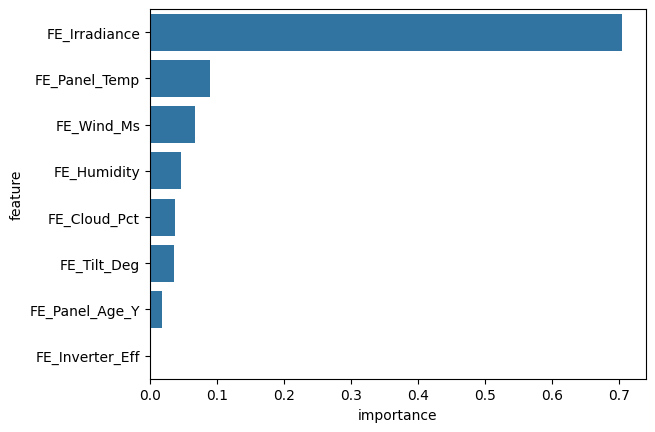

In [51]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

fi = pd.DataFrame({'feature': X.columns, 'importance': dt.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:8]
sns.barplot(x='importance', y='feature', data=fi)
plt.show()

In [52]:
# (11) 정답을 입력하세요 — `정답11` 에 값만 넣고 실행하세요

정답11 = 'FE_irradiance'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

변수 중요도를 DataFrame 으로 만들고 정렬해 그리는 흐름을 점검하세요. fi 의 첫 번째 행(가장 큰 중요도)의 feature 값을 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `sort_values`, `iloc`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

fi = pd.DataFrame({'feature': X.columns, 'importance': dt.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:8]
sns.barplot(x='importance', y='feature', data=fi)
plt.show()

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
fi['____'].iloc[__]
```

</details>

### **12. 앞서 학습시킨 KNN와(과) DecisionTree 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, mean_absolute_error) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `dt`, `knn`
- 아래 안내대로 각 모델의 MAE(평균절대오차) 를 산출하려는데 에러가 나고 있습니다. 코드의 오류를 수정하세요
    - 앞서 학습시킨 knn 와 dt 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 MAE(평균절대오차) 값을 각각 knn_score, dt_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 MAE(평균절대오차) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (KNN / DecisionTree 중 하나)
- 답안 : **[정답12]** 의 값만 답안 셀에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [53]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import mean_absolute_error

y_pred_knn = knn.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

knn_score = mean_absolute_error(y_valid, y_pred_knn)
dt_score = mean_absolute_error(y_valid, y_pred_dt)
print(knn_score, dt_score)

193.4753527336861 184.05298095065564


In [55]:
# (12) 정답을 입력하세요 — `정답12` 에 값만 넣고 실행하세요

정답12 = 'DecisionTree'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

MAE(평균절대오차) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 작을수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import mean_absolute_error

y_pred_knn = knn.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

knn_score = mean_absolute_error(y_valid, y_pred_knn)
dt_score = mean_absolute_error(y_valid, y_pred_dt)
print(knn_score, dt_score)

# [정답12] 실행한 결과를 입력하세요
print(knn_score, dt_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [56]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(7)

### **13. 시간당 발전량(kW)(Power_Kw)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 가이드에 맞춰 신경망을 구성한 뒤 학습까지 진행하세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 보통 | 예상 시간: 13분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- tensorflow framework 를 사용하세요
- 은닉층은 Dense 레이어 2개(노드 수 [32, 16]), 활성화 함수는 'selu' 로 하세요
- 조기 종료 : EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True) 를 만들어 estop 에 보관하세요
- 이번 모델에는 Dropout 을 넣지 않습니다
- 출력층: 노드 1개 (회귀이므로 활성화 함수 없음)
- 모델을 컴파일할 때 optimizer 는 rmsprop, 손실 함수는 mse, 평가지표는 [mae] 로 하세요
- batch_size 는 16, epochs 는 20 로 학습하고 학습정보는 history 변수에 저장하세요 (검증 데이터: X_valid, 검증 레이블)
- 안내하지 않은 파라미터는 지정하지 마세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답13]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답13]** 의 값만 답안 셀에 `정답13 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [57]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

model = Sequential([
    Dense(32, activation='selu', input_dim=X_train.shape[1]),
    Dense(16, activation='selu'),
    Dense(1)
])

estop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='rmsprop', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=16,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 323548.8438 - mae: 477.9765 - val_loss: 402225.5625 - val_mae: 516.8455
Epoch 2/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 322212.3438 - mae: 476.8994 - val_loss: 400337.8750 - val_mae: 515.4197
Epoch 3/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 320270.5312 - mae: 475.2961 - val_loss: 397647.3750 - val_mae: 513.3228
Epoch 4/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 317549.2500 - mae: 472.9824 - val_loss: 394025.8438 - val_mae: 510.4202
Epoch 5/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 313971.0938 - mae: 469.8483 - val_loss: 389380.4375 - val_mae: 506.6155
Epoch 6/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 309468.5000 - mae: 465.8130 - val_loss: 383656.1562 - val_mae: 501.8540
Epoch 7/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 303957.9688 - mae: 460.8071 - val_loss: 376744.5938 - val_mae: 496.0505
Epoch 8/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 297351.5625 - mae: 454.7571 -

In [58]:
# (13) 정답을 입력하세요 — `정답13` 에 값만 넣고 실행하세요

정답13 = 'rmsprop'

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드의 모델 구조·학습 조건을 코드의 각 줄과 대응시켜 보세요. 모델을 학습시킬 때 가중치를 갱신하는 최적화 알고리즘의 이름입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`. 정답은 7글자이고 첫 글자는 `r` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
model = Sequential([
    Dense(32, activation='selu', input_dim=X_train.shape[1]),
    Dense(16, activation='selu'),
    Dense(1)
])

estop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='rmsp___', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=16,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

정답13 = 'rmsp___'   # 빈칸에 넣은 단어
```

</details>

### **14. 학습이 끝난 모델의 최종 성능을 검증 데이터로 한 번 더 확인할 계획입니다.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: TensorFlow(Keras)(evaluate) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 13번 `model`
- 학습된 `model` 의 `evaluate` 로 검증 데이터(X_valid, y_valid)의 성능을 산출하세요 (verbose=0)
    - 반환되는 값은 loss 와 compile 에서 지정한 metrics(mae) 순서입니다. 각각 `loss, mae` 변수에 저장하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답14]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답14]** 의 값만 답안 셀에 `정답14 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [59]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

loss, mae = model.evaluate(X_valid, y_valid, verbose=0)

In [60]:
# (14) 정답을 입력하세요 — `정답14` 에 값만 넣고 실행하세요

정답14 = 'verbose'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

학습된 모델에 검증 데이터를 넣어 손실과 지표를 한 번에 구합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `model.evaluate`. 정답은 7글자이고 첫 글자는 `v` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
loss, mae = model.evaluate(X_valid, y_valid, verb___=0)

정답14 = 'verb___'   # 빈칸에 넣은 단어
```

</details>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### 답안을 저장한 뒤 제출해 주시기 바랍니다.